In [1]:
# From ref design
from pynq import Overlay
import xrfclk
from pynq import PL

# ADC
from adc_scope import AdcScope
import matplotlib.pyplot as plt
%matplotlib inline

# DAC
import numpy as np
from rfsoc_awg import *      # AWG, Pulse and the unit helpers ns, us, kHz, MHz, GHz

In [2]:
PL.reset()
xrfclk.set_ref_clks(lmk_freq=245.76, lmx_freq=491.52)   #Programs the oscillators on the board to produce the appropriate clock signals
ol = Overlay("awg_adc_v5.bit")         # after xrfclk.set_ref_clks(...) as usual

In [3]:
sc = AdcScope(ol)                      # starts the ADC clock (MMCM) and checks the ADC streams

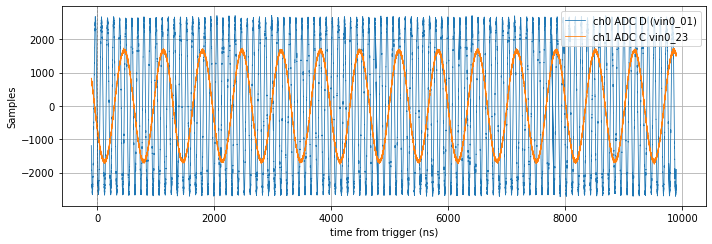

In [13]:
## CHECK SETUP
sc.configure(trigger="immediate", length_ns=10000)
t, y = sc.acquire(raw=True) # t in ns, 0 = trigger; y in fraction of full scale

sc.plot(t, y, ylabel="Samples")

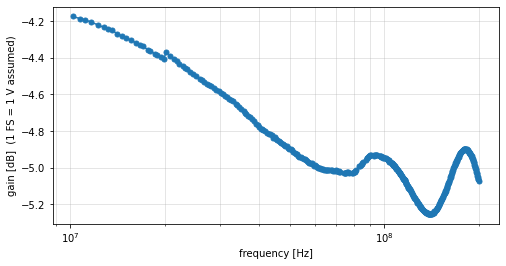

noise floor (median peak): 0.07544 FS


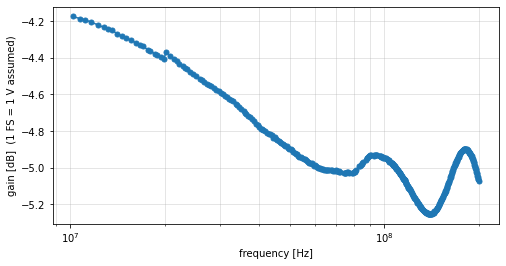

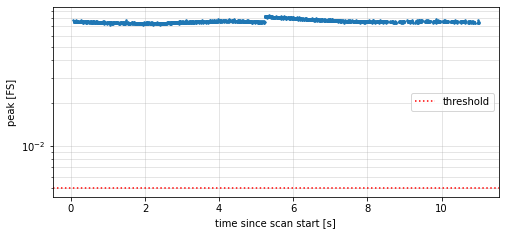

In [35]:
## OUR BODE SCAN
from bode_point import Bode
b = Bode(sc, gen_vpk=0.125, channel=0)
b.scan(duration_s=11)           # start the generator's sweep, then run this
b.plot_trace()      # peak of every capture vs time, with the threshold line
b.save("bodeLogADC_D10Mto200M.csv")

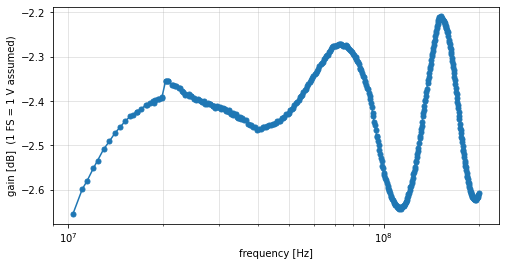

noise floor (median peak): 0.09656 FS


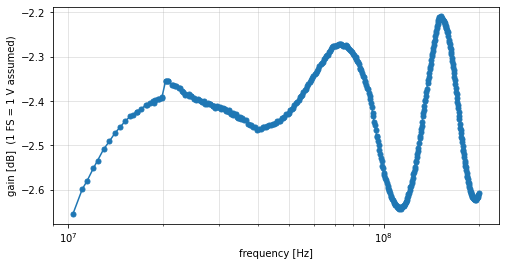

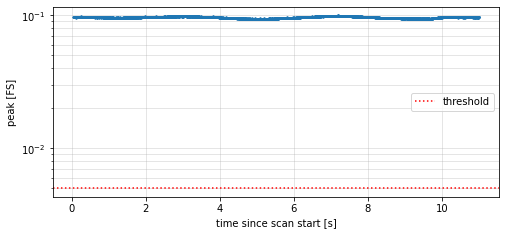

In [36]:
## OUR BODE SCAN
from bode_point import Bode
b = Bode(sc, gen_vpk=0.125, channel=1)
b.scan(duration_s=11)           # start the generator's sweep, then run this
b.plot_trace()      # peak of every capture vs time, with the threshold line
b.save("bodeLogADC_C10Mto200M.csv")

In [ ]:
# ## OUR BODE SCAN, modified channel
# from bode_point import Bode
# b = Bode(sc, gen_vpk=0.25, channel=0)
# b.scan(duration_s=22)           # start the generator's sweep, then run this
# b.plot_trace()      # peak of every capture vs time, with the threshold line
# b.save("bodeLinADCD.csv") # SCAN 1kHz to 200MHz over 20s

In [ ]:
# ## OUR BODE SCAN
# from bode_point import Bode
# b = Bode(sc, gen_vpk=0.25, channel=0)
# b.scan(duration_s=22)           # start the generator's sweep, then run this
# b.plot_trace()      # peak of every capture vs time, with the threshold line
# b.save("bodeLogADCD.csv") # SCAN 1kHz to 200MHz over 20s

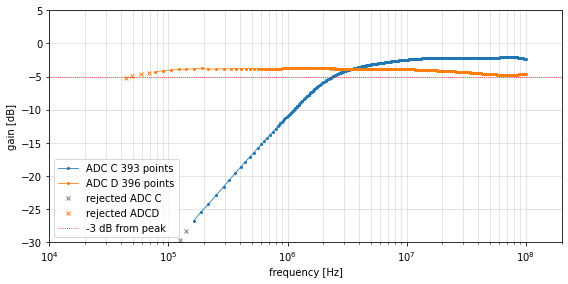

In [39]:
show_rejected=True

d = np.genfromtxt("bodeLogADC_C40kto100M.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f, g = d["freq_hz"].astype(float), d["gain_db"].astype(float)
ok = np.array([str(v).lower() == "true" for v in d["accepted"]]) & np.isfinite(f) & np.isfinite(g)
o = np.argsort(f[ok])
fig, ax = plt.subplots(figsize=(8, 4))

D_adcd = np.genfromtxt("bodeLogADC_D40kto100M.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f_adcd, g_adcd = D_adcd["freq_hz"].astype(float), D_adcd["gain_db"].astype(float)
ok_adcd = np.array([str(v).lower() == "true" for v in D_adcd["accepted"]]) & np.isfinite(f_adcd) & np.isfinite(g_adcd)
o_adcd = np.argsort(f_adcd[ok_adcd])

ax.semilogx(f[ok][o], g[ok][o], ".-", ms=4, lw=0.8, label=f"ADC C {ok.sum()} points")
ax.semilogx(f_adcd[ok_adcd][o_adcd], g_adcd[ok_adcd][o_adcd], ".-", ms=4, lw=0.8, label=f"ADC D {ok_adcd.sum()} points")
if show_rejected:
    bad = ~ok & np.isfinite(f) & np.isfinite(g)
    ax.semilogx(f[bad], g[bad], "x", color="grey", ms=4, label="rejected ADC C")
    bad_adcd = ~ok_adcd & np.isfinite(f_adcd) & np.isfinite(g_adcd)
    ax.semilogx(f_adcd[bad_adcd], g_adcd[bad_adcd], "x", color="tab:orange", ms=4, label="rejected ADCD")
pk = g[ok].max()
ax.axhline(pk - 3, color="r", ls=":", lw=0.8, label="-3 dB from peak")
ax.set_xlabel("frequency [Hz]"); ax.set_ylabel("gain [dB]")
ax.grid(True, which="both", alpha=0.4); ax.legend()
fig.tight_layout()


plt.xlim(10e3, 200e6)
plt.ylim(-30, 5)
plt.show()

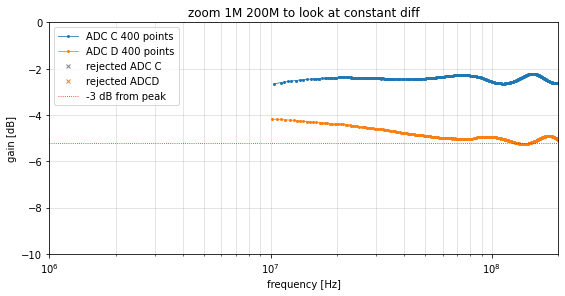

In [38]:
show_rejected=True

d = np.genfromtxt("bodeLogADC_C10Mto200M.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f, g = d["freq_hz"].astype(float), d["gain_db"].astype(float)
ok = np.array([str(v).lower() == "true" for v in d["accepted"]]) & np.isfinite(f) & np.isfinite(g)
o = np.argsort(f[ok])
fig, ax = plt.subplots(figsize=(8, 4))

D_adcd = np.genfromtxt("bodeLogADC_D10Mto200M.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f_adcd, g_adcd = D_adcd["freq_hz"].astype(float), D_adcd["gain_db"].astype(float)
ok_adcd = np.array([str(v).lower() == "true" for v in D_adcd["accepted"]]) & np.isfinite(f_adcd) & np.isfinite(g_adcd)
o_adcd = np.argsort(f_adcd[ok_adcd])

ax.semilogx(f[ok][o], g[ok][o], ".-", ms=4, lw=0.8, label=f"ADC C {ok.sum()} points")
ax.semilogx(f_adcd[ok_adcd][o_adcd], g_adcd[ok_adcd][o_adcd], ".-", ms=4, lw=0.8, label=f"ADC D {ok_adcd.sum()} points")
if show_rejected:
    bad = ~ok & np.isfinite(f) & np.isfinite(g)
    ax.semilogx(f[bad], g[bad], "x", color="grey", ms=4, label="rejected ADC C")
    bad_adcd = ~ok_adcd & np.isfinite(f_adcd) & np.isfinite(g_adcd)
    ax.semilogx(f_adcd[bad_adcd], g_adcd[bad_adcd], "x", color="tab:orange", ms=4, label="rejected ADCD")
pk = g[ok].max()
ax.axhline(pk - 3, color="r", ls=":", lw=0.8, label="-3 dB from peak")
ax.set_xlabel("frequency [Hz]"); ax.set_ylabel("gain [dB]")
ax.grid(True, which="both", alpha=0.4); ax.legend()
fig.tight_layout()


plt.xlim(1e6, 200e6)
plt.ylim(-10, 0)
plt.title("zoom 1M 200M to look at constant diff")
plt.show()

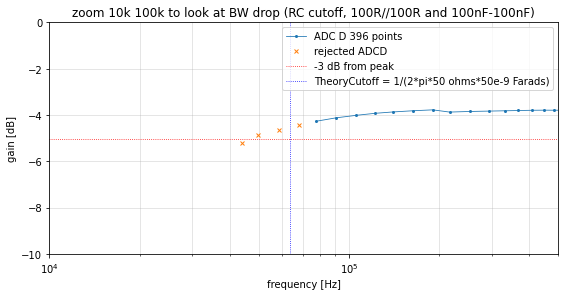

In [63]:
show_rejected=True

d = np.genfromtxt("bodeLogADC_C40kto100M.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f, g = d["freq_hz"].astype(float), d["gain_db"].astype(float)
ok = np.array([str(v).lower() == "true" for v in d["accepted"]]) & np.isfinite(f) & np.isfinite(g)
o = np.argsort(f[ok])
fig, ax = plt.subplots(figsize=(8, 4))

D_adcd = np.genfromtxt("bodeLogADC_D40kto100M.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f_adcd, g_adcd = D_adcd["freq_hz"].astype(float), D_adcd["gain_db"].astype(float)
ok_adcd = np.array([str(v).lower() == "true" for v in D_adcd["accepted"]]) & np.isfinite(f_adcd) & np.isfinite(g_adcd)
o_adcd = np.argsort(f_adcd[ok_adcd])

# ax.semilogx(f[ok][o], g[ok][o], ".-", ms=4, lw=0.8, label=f"ADC C {ok.sum()} points")
ax.semilogx(f_adcd[ok_adcd][o_adcd], g_adcd[ok_adcd][o_adcd], ".-", ms=4, lw=0.8, label=f"ADC D {ok_adcd.sum()} points")
if show_rejected:
    bad = ~ok & np.isfinite(f) & np.isfinite(g)
    # ax.semilogx(f[bad], g[bad], "x", color="grey", ms=4, label="rejected ADC C")
    bad_adcd = ~ok_adcd & np.isfinite(f_adcd) & np.isfinite(g_adcd)
    ax.semilogx(f_adcd[bad_adcd], g_adcd[bad_adcd], "x", color="tab:orange", ms=4, label="rejected ADCD")
pk = g[ok].max()
ax.axhline(pk - 3, color="r", ls=":", lw=0.8, label="-3 dB from peak")
ax.axvline(1/(2*np.pi*50*50e-9), color="b", ls=":", lw=0.8, label="TheoryCutoff = 1/(2*pi*50 ohms*50e-9 Farads)")
# print(1/(2*np.pi*50*50e-9))
# ax.axvline(50e3, color="b", ls=":", lw=0.8, label="MeasuredCutoff")
ax.set_xlabel("frequency [Hz]"); ax.set_ylabel("gain [dB]")
ax.grid(True, which="both", alpha=0.4); ax.legend()
fig.tight_layout()


plt.xlim(10e3, 500e3)
plt.ylim(-10, 0)
plt.title("zoom 10k 100k to look at BW drop (RC cutoff, 100R//100R and 100nF-100nF)")
plt.show()

In [28]:
# ## CHECK 1 OUTPUT
# sc.configure(trigger="immediate", length_ns=1000)
# t, y = sc.acquire() # t in ns, 0 = trigger; y in fraction of full scale

# sc.plot(t, y*32768.0, ylabel="Samples")
# sc.plot(t, y/1.7, ylabel="Amplitude (Volts)") # Experimentally 0.1V @10MHz gave 0.17FS

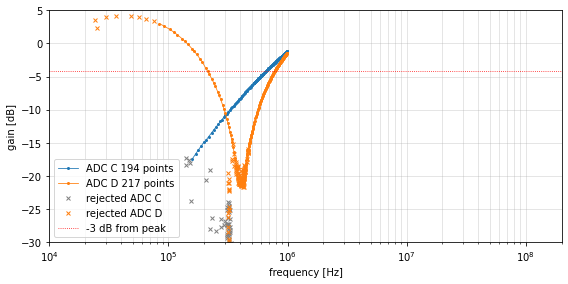

In [64]:
show_rejected=True

d = np.genfromtxt("bodeLogADC_C_kHz.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f, g = d["freq_hz"].astype(float), d["gain_db"].astype(float)
ok = np.array([str(v).lower() == "true" for v in d["accepted"]]) & np.isfinite(f) & np.isfinite(g)
o = np.argsort(f[ok])
fig, ax = plt.subplots(figsize=(8, 4))

D_adcd = np.genfromtxt("bodeLogADC_D_kHz.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f_adcd, g_adcd = D_adcd["freq_hz"].astype(float), D_adcd["gain_db"].astype(float)
ok_adcd = np.array([str(v).lower() == "true" for v in D_adcd["accepted"]]) & np.isfinite(f_adcd) & np.isfinite(g_adcd)
o_adcd = np.argsort(f_adcd[ok_adcd])

ax.semilogx(f[ok][o], g[ok][o], ".-", ms=4, lw=0.8, label=f"ADC C {ok.sum()} points")
ax.semilogx(f_adcd[ok_adcd][o_adcd], g_adcd[ok_adcd][o_adcd], ".-", ms=4, lw=0.8, label=f"ADC D {ok_adcd.sum()} points")
if show_rejected:
    bad = ~ok & np.isfinite(f) & np.isfinite(g)
    ax.semilogx(f[bad], g[bad], "x", color="grey", ms=4, label="rejected ADC C")
    bad_adcd = ~ok_adcd & np.isfinite(f_adcd) & np.isfinite(g_adcd)
    ax.semilogx(f_adcd[bad_adcd], g_adcd[bad_adcd], "x", color="tab:orange", ms=4, label="rejected ADC D")
pk = g[ok].max()
ax.axhline(pk - 3, color="r", ls=":", lw=0.8, label="-3 dB from peak")
ax.set_xlabel("frequency [Hz]"); ax.set_ylabel("gain [dB]")
ax.grid(True, which="both", alpha=0.4); ax.legend()
fig.tight_layout()


plt.xlim(10e3, 200e6)
plt.ylim(-30, 5)
plt.show()

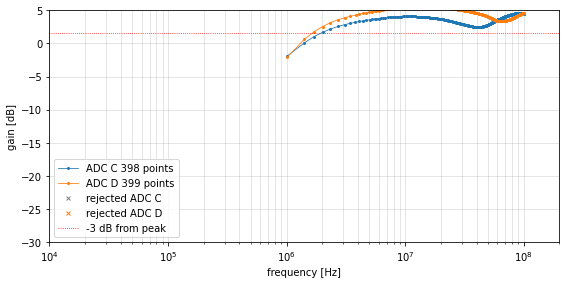

In [65]:
show_rejected=True

d = np.genfromtxt("bodeLogADC_C_MHz.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f, g = d["freq_hz"].astype(float), d["gain_db"].astype(float)
ok = np.array([str(v).lower() == "true" for v in d["accepted"]]) & np.isfinite(f) & np.isfinite(g)
o = np.argsort(f[ok])
fig, ax = plt.subplots(figsize=(8, 4))

D_adcd = np.genfromtxt("bodeLogADC_D_MHz.csv", delimiter=",", names=True, dtype=None, encoding="utf-8")
f_adcd, g_adcd = D_adcd["freq_hz"].astype(float), D_adcd["gain_db"].astype(float)
ok_adcd = np.array([str(v).lower() == "true" for v in D_adcd["accepted"]]) & np.isfinite(f_adcd) & np.isfinite(g_adcd)
o_adcd = np.argsort(f_adcd[ok_adcd])

ax.semilogx(f[ok][o], g[ok][o], ".-", ms=4, lw=0.8, label=f"ADC C {ok.sum()} points")
ax.semilogx(f_adcd[ok_adcd][o_adcd], g_adcd[ok_adcd][o_adcd], ".-", ms=4, lw=0.8, label=f"ADC D {ok_adcd.sum()} points")
if show_rejected:
    bad = ~ok & np.isfinite(f) & np.isfinite(g)
    ax.semilogx(f[bad], g[bad], "x", color="grey", ms=4, label="rejected ADC C")
    bad_adcd = ~ok_adcd & np.isfinite(f_adcd) & np.isfinite(g_adcd)
    ax.semilogx(f_adcd[bad_adcd], g_adcd[bad_adcd], "x", color="tab:orange", ms=4, label="rejected ADC D")
pk = g[ok].max()
ax.axhline(pk - 3, color="r", ls=":", lw=0.8, label="-3 dB from peak")
ax.set_xlabel("frequency [Hz]"); ax.set_ylabel("gain [dB]")
ax.grid(True, which="both", alpha=0.4); ax.legend()
fig.tight_layout()


plt.xlim(10e3, 200e6)
plt.ylim(-30, 5)
plt.show()